<a href="https://colab.research.google.com/github/irenerope/intro-machine-learning-language-processing/blob/main/Introduction%20to%20ML%20for%20NLP/02_Language_Identification_with_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/liadmagen/NLP-Course/blob/master/02_Language_Identification_with_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Language Identification with a Decision Tree

In this exercise you will identify the **language of a text** using only surface-level **orthography and phonotactics** — diacritics, character clusters, and vowel patterns — not neural embeddings. We use a pre-filtered **Latin-script subset of the Papluca Language Identification dataset** (`lang_train.csv` / `lang_test.csv`, sitting next to this notebook; 8 languages: de, en, es, fr, it, nl, sw). Each CSV has the columns `language,text`.

The exercise follows the **PRIMM** cycle:
- **P**redict what code will do,
- **R**un it to check,
- **I**nvestigate it line by line,
- **M**odify it in small steps, and finally
- **M**ake something of your own.

### Environment
If you don't use Google Colab for this exercise, you will need to install libraries like pandas, scikit-learn, and matplotlib. Using [uv](https://docs.astral.sh/uv/), you can add them by running: `uv add pandas scikit-learn matplotlib`).

### Goal
By the end of this exercise, you will:
* explore a dataset with basic pandas commands (`value_counts`, `map`/`apply`, `groupby`, `plot`)
* explain how surface orthography and phonotactics (diacritics, character clusters, vowel ratios) can distinguish languages without embeddings
* craft ratio-normalized text features with pandas that stay comparable across different sentence lengths
* follow the scikit-learn pattern of initialize → `.fit()` → `.predict()`, and explain how a decision tree splits on features using the Gini impurity
* train, visualize, and interpret a transparent `DecisionTreeClassifier` in scikit-learn
* evaluate a classifier with a classification report and a confusion matrix, and reflect linguistically on its errors


## A note on using AI tools in this notebook

You're welcome to use ChatGPT, Copilot, Claude Code or a similar tool while working through this notebook — they're genuinely good for explaining an error message, or for the **AI Code Audit** section near the end, which is built specifically around AI-generated code.

For cells marked **Make** (or **YOUR TURN**), please attempt the logic yourself first — even a wrong or incomplete attempt — before asking an AI to write or fix it for you. That struggle is where most of the actual learning happens. If you do end up using AI on a **Make** cell, add a one-line comment saying where and how. There's no penalty for using AI — the goal is that you can explain *why* the code works, not just that it runs.


## Setup — load the dataset

The two CSVs must sit **next to this notebook**. Locally that means the same folder; in Google Colab, upload them via the Files panel (left sidebar) after opening the notebook.

In [4]:
from pathlib import Path
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.tree import DecisionTreeClassifier, plot_tree


def load_lang_csv(filename: str) -> pd.DataFrame:
    # Load one of the Papluca LID CSVs that sits next to this notebook.
    path = Path(filename)
    if not path.exists():
        raise FileNotFoundError(
            f"'{filename}' not found next to the notebook. In Colab, upload it via the "
            "Files panel (left sidebar); locally, place it in the same folder as the notebook."
        )
    return pd.read_csv(path)


train = load_lang_csv("lang_train.csv")
test = load_lang_csv("lang_test.csv")

print(f"train: {train.shape},  test: {test.shape}")
train.head()

train: (24500, 2),  test: (3500, 2)


,language,text
0,sw,Zabuni ya ushindani pia imekuwa rahisi kwa sif...
1,es,Un producto de una calidad y capacidad increíb...
2,it,Una donna sta affettando della carne.
3,de,"Alles in allem ein super schönes Teil, deshalb..."
4,de,Einer Freundin Geschenk da sie Flugbegleiterin...


## Part 0 — Pandas basics, and why phonotactics?

**The data.** `train` and `test` are pandas **[DataFrames](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html)** — tables where each row is one review and each column (`language`, `text`) is a pandas **[Series](https://pandas.pydata.org/docs/reference/series.html)**. `df["col"]` selects one column, `df.shape` gives (rows, columns), `df.head(n)` shows the first n rows.

**Why phonotactics?** *Phonotactics* is the study of which sound sequences are allowed in a language. Written language preserves a surface trace of it: German almost always writes /ʃ/ as `sch`, Spanish uses `ñ` and `ll`, French `ç` and `tion`, Dutch `ij` and `oe`. A short text can therefore carry strong evidence about its language — *if* we turn characters into numbers a model can use. That is exactly what a **feature function** does (the same idea as in the gender-identification notebook, but now on whole sentences).

Two complications we will meet head-on: **loanwords** (e.g. English `software` inside a German review) break naive character rules, and **missing diacritics** (text typed without accents, or stripped by some platform) erase otherwise decisive signals. Let's explore the data first.


In [5]:
print("shape:", train.shape)                      # (number of rows, number of columns)
print("columns:", list(train.columns))
print("type of one column:", type(train["text"]))  # a pandas Series: one value per row
train.head(3)

shape: (24500, 2)
columns: ['language', 'text']
type of one column: <class 'pandas.core.series.Series'>


,language,text
0,sw,Zabuni ya ushindani pia imekuwa rahisi kwa sif...
1,es,Un producto de una calidad y capacidad increíb...
2,it,Una donna sta affettando della carne.


**Predict**, before running the next cell: `train['language'].value_counts()` counts how many rows carry each language label. Predict: which language has the **most** training samples, and how many?

*Your prediction:*  I think the dataset is balanced, so all languages will have the same number of samples.


In [7]:
train["language"].value_counts()  # Run: check your prediction

,count
language,
sw,3500
es,3500
it,3500
de,3500
nl,3500
fr,3500
en,3500


The dataset is **balanced**: 3500 training and 500 test samples per language — so plain accuracy is a meaningful metric here.

### Counting diacritics per language with `.map()`

`series.map(func)` applies `func` to **every element** of a Series and returns a new Series (`series.apply(func)` does the same for a Series). Taking `.mean()` of a boolean Series gives the **fraction** of `True` values — perfect for "in how many texts does this character appear?"

**Predict**, before running the next cell: the next cell builds a table: for each marker in ñ, ß, ç, ll, sch, ij, the fraction of each language's texts containing it. Predict: in which language(s) does `ñ` appear **at all**, and is its fraction 1.0? Same question for `ß` and for `ij`.

*Your prediction:*  "ñ" will appear in Spanish, "ß" in German, and "ij" in Dutch. I think none of them will have a fraction of 1.0, because not every sentence would contains these letters. Maybe they appear also in other languages, since, for example, German and Dutch are germanic languages and they have some cognates.

In [8]:
MARKERS = ["ñ", "ß", "ç", "ll", "sch", "ij"]
marker_presence = pd.DataFrame({
    m: train["text"].map(lambda t, m=m: m in t.lower()).groupby(train["language"]).mean()
    for m in MARKERS
})
marker_presence.round(3)  # fraction of each language's texts containing the marker

,ñ,ß,ç,ll,sch,ij
language,,,,,,
de,0.000,0.192,0.000,0.563,0.699,0.000
en,0.000,0.000,0.000,0.507,0.007,0.000
es,0.181,0.000,0.000,0.328,0.001,0.038
fr,0.000,0.000,0.225,0.355,0.001,0.002
it,0.000,0.000,0.000,0.437,0.019,0.001
nl,0.000,0.000,0.000,0.111,0.176,0.336
sw,0.000,0.000,0.000,0.104,0.003,0.053


Each marker lights up in different languages (ñ → es, ß → de, ç → fr, ij → nl, sch → de/nl) — but no fraction is 1.0: real text contains **loanwords and unaccented typing**, which is exactly why single-character heuristics fail and we will need many soft features.

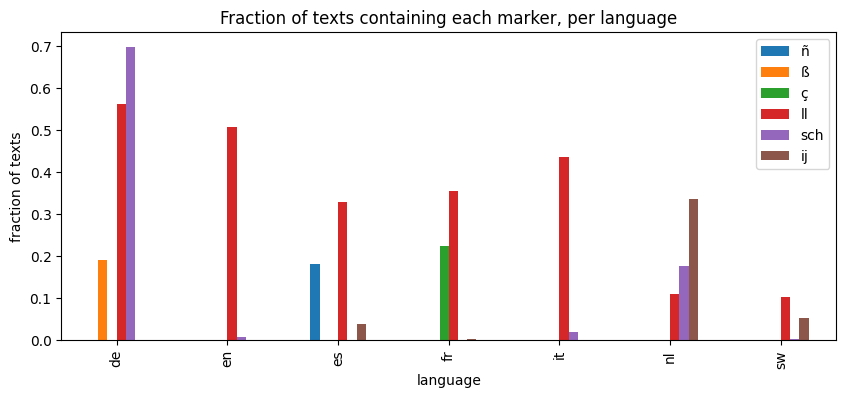

In [10]:
marker_presence.plot(kind="bar", figsize=(10, 4))  # pandas plots via matplotlib under the hood
plt.title("Fraction of texts containing each marker, per language")
plt.ylabel("fraction of texts")
plt.show()

### Your turn — explore the data with pandas (not graded)

Fill in the cell below (the comments are the recipe). Try all four:
1. `test["language"].value_counts()` — is the test set balanced too?
2. With `.map()` (or `.apply()`), compute **per language** the fraction of texts containing `"¿"` and `"tion"`: `train["text"].map(lambda t: "¿" in t).groupby(train["language"]).mean()`
3. Mean text length per language: `train["text"].str.len().groupby(train["language"]).mean()`, then plot it with `.plot(kind="bar")`
4. Histogram of all text lengths: `train["text"].str.len().plot(kind="hist", bins=50)`

These are exploration commands, not a Make task — experiment freely.

language
nl    500
es    500
it    500
fr    500
en    500
sw    500
de    500
Name: count, dtype: int64
language
de    0.000000
en    0.000000
es    0.002286
fr    0.000000
it    0.000000
nl    0.000000
sw    0.000000
Name: text, dtype: float64
language
de    0.116286
en    0.130571
es    0.002857
fr    0.275714
it    0.007143
nl    0.019714
sw    0.025714
Name: text, dtype: float64
language
de    205.826857
en    180.069429
es    151.092286
fr    159.574857
it     69.972286
nl     66.827429
sw    107.212000
Name: text, dtype: float64


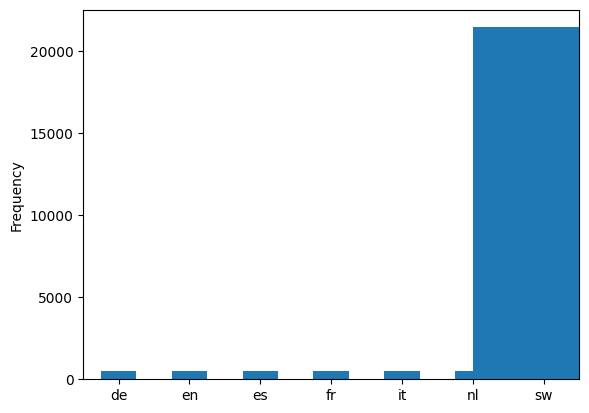

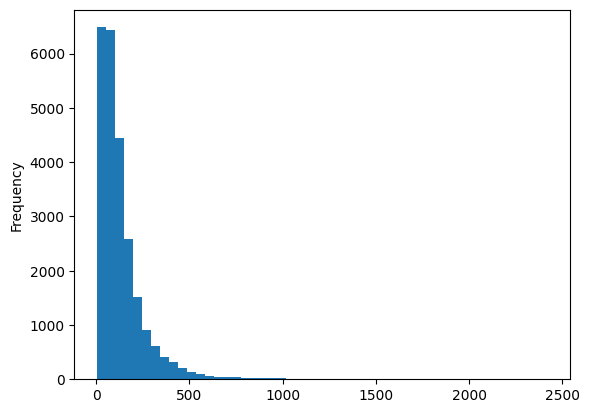

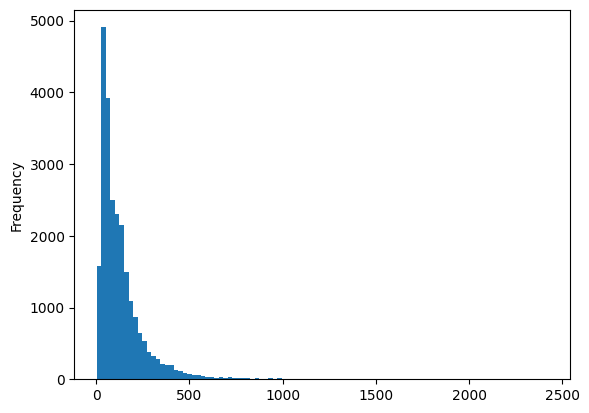

In [14]:
### Explore: pandas basics (fill in the TODOs)

# 1) TODO: print the number of texts per language, then .plot(kind="bar")
print(test["language"].value_counts())
test["language"].value_counts().plot(kind="bar")

# 2) TODO: per language, fraction of texts containing "¿" and "tion"
#    hint: use the .map() method to check for the presence of a substring in each text, then groupby() and mean()
print(train["text"].map(lambda t: "¿" in t).groupby(train["language"]).mean())
print(train["text"].map(lambda t: "tion" in t).groupby(train["language"]).mean())

# 3) TODO: mean text length per language, then .plot(kind="bar")
print(train["text"].str.len().groupby(train["language"]).mean())
train["text"].str.len().groupby(train["language"]).mean().plot(kind="bar")

# 4) TODO: histogram of text lengths with .plot() of 'hist' kind, and try different values of bins=... to see how it affects the histogram
train["text"].str.len().plot(kind="hist", bins=10)
plt.show()

train["text"].str.len().plot(kind="hist", bins=50)
plt.show()

train["text"].str.len().plot(kind="hist", bins=100)
plt.show()

### Predict: can a few diacritics identify a language?

Consider this deliberately naive, character-level heuristic:

```python
def quick_guess(text: str) -> str:
    if 'ñ' in text or '¿' in text:
        return 'es'
    if 'ß' in text:
        return 'de'
    if 'ç' in text or 'ù' in text:
        return 'fr'
    return 'en'
```


**Predict**, before running the next cell: the next cell applies `quick_guess` to the first test sentence of six languages (en, nl, de, es, it, sw) and prints `true` vs `guess`. Before running: what will `quick_guess` return for the **Dutch, Italian, and Swahili** sentences — and why? Write down your three guesses.

*Your prediction:*  I think *quick_guess* will return "en" for the Dutch, Italian and Swahili sentences, since they don't contain "ñ", "¿", "ß", "ç" or "ù", so it relapses to the default answer "en". Italian could be guessed as "fr" if "ù" appears in the sentence.


### Run: validate the prediction

In [20]:
def quick_guess(text: str) -> str:
    # A deliberately naive, character-level heuristic:
    if "ñ" in text or "¿" in text:
        return "es"
    if "ß" in text:
        return "de"
    if "ç" in text or "ù" in text:
        return "fr"
    return "en"


samples = [(lang, test[test.language == lang].text.iloc[0])
           for lang in ["en", "nl", "de", "es", "it", "sw"]]
for lang, text in samples:
    print(f"true={lang:<3} guess={quick_guess(text):<3} | {text[:60]}")

true=en  guess=en  | This review is for Amazon directly rather than the product. 
true=nl  guess=en  | Een man zingt en speelt gitaar.
true=de  guess=de  | Der Stoff ist sehr dünn. Sie rutschen runter und man bekommt
true=es  guess=es  | Es muy resistente la parte trasera rígida y los laterales de
true=it  guess=en  | "In tanti modi diversi, l'abilità artistica dei musicisti ne
true=sw  guess=en  | Shinikizo kuu linafaa ndege,kana lile  wana anga wanafaa kul


Now measure the heuristic on the **whole test set** (3500 sentences) instead of six examples:

In [19]:
guesses = test.text.map(quick_guess)
print("heuristic accuracy on the test set:", round(accuracy_score(test.language, guesses), 3))
print("(random guessing among 8 languages would give", round(1 / 8, 3), ")")
pd.crosstab(test.language, guesses)  # which true languages get which guess?

heuristic accuracy on the test set: 0.226
(random guessing among 8 languages would give 0.125 )


text,de,en,es,fr
language,,,,
de,89,411,0,0
en,0,500,0,0
es,0,402,98,0
fr,0,396,0,104
it,0,485,0,15
nl,0,500,0,0
sw,0,500,0,0


As expected, everything without one of the four trigger characters collapses to `'en'` — the heuristic reaches only about **23%** (vs. 12.5% for random guessing). Single-character rules are not enough: we need *many* soft features and a model that combines them.

### Investigate: from one heuristic to a feature vector

Instead of one hard rule, we extract a **vector of ratio-normalized features** per text. Normalization (dividing by the text length) matters: a 100-word review naturally contains more of everything than a 5-word one, and raw counts would just measure *length*, not *language*.

In [21]:
VOWELS = set("aeiouy") | set("áéíóúàèìòùâêîôûäëïöüãõåøæ")  # ñ, ß, ç are consonants


def phonotactic_features(text: str) -> dict:
    # Hand-crafted, ratio-normalized orthographic features for one text snippet.
    text = text.lower()
    n_chars = max(len(text), 1)            # normalize per character, so lengths don't dominate
    words = [w for w in text.split() if w]
    n_words = max(len(words), 1)
    nfd = unicodedata.normalize("NFD", text)  # decompose 'é' -> 'e' + combining accent
    features = {
        "vowel_ratio":       sum(c in VOWELS for c in text) / n_chars,
        "diacritic_ratio":   sum(unicodedata.category(c) == "Mn" for c in nfd) / n_chars,
        "avg_word_length":   sum(len(w) for w in words) / n_words,
        "final_vowel_ratio": sum(w[-1] in VOWELS for w in words) / n_words,
        # three example character clusters, as a taste of what is possible:
        "marker_ñ":   text.count("ñ") / n_chars,
        "marker_ß":   text.count("ß") / n_chars,
        "marker_sch": text.count("sch") / n_chars,
    }
    return features


langs = ["es", "de", "en"]
examples = [test[test.language == lang].text.iloc[0] for lang in langs]
pd.DataFrame([phonotactic_features(t) for t in examples], index=langs)

,vowel_ratio,diacritic_ratio,avg_word_length,final_vowel_ratio,marker_ñ,marker_ß,marker_sch
es,0.398148,0.018519,4.736842,0.631579,0.009259,0.000000,0.000000
de,0.259740,0.025974,5.000000,0.153846,0.000000,0.012987,0.025974
en,0.317690,0.000000,5.318182,0.227273,0.000000,0.000000,0.000000


C**Investigate** — before running the next cell, trace the code above and answer:

1. By hand, compute `phonotactic_features("El niño")`: what is `vowel_ratio`? (`"el niño"` has 7 characters; how many are in `VOWELS`?)

    "el niño" has 7 characters (counting spaces). The vowels are e, i, o. So 3 vowels. So vowel_ratio = 3/7 = 0.43.

2. Why is every count divided by a length instead of kept as a raw count? What would a raw `text.count("ñ")` feature measure in a 100-word review vs. a 5-word one?

    A raw count would measure the length of the text, not the language. A 100-word Spanish review will contain more "ñ" than a 5-word one. Dividing by the length gives us a proportion, so short and long texts can be compared.

3. `diacritic_ratio` counts Unicode *combining marks* after NFD decomposition. What happens to this feature for loanwords written without accents (e.g. `cafe` instead of `café`), or when a platform strips diacritics? Run the cell below and compare.

    Without accents, diacritic_ratio fells to 0, so this feature loses its signal and the text could seem to be English. Also, when taking accents away "ñ" becomes "n", so marker_ñ would turn 0 too.

4. The three marker features are 0 for most texts. Why can a decision tree still use a mostly-zero feature very effectively?

    When the feature is not 0, it is a very strong clue. The tree can ask "marker_ñ > 0?": if yes, the text is almost certainly Spanish; if no, the tree just continues asking. So it really doesn't matter that most texts have 0.

In [22]:
def strip_accents(text: str) -> str:
    # Remove combining marks: 'café' -> 'cafe'
    return "".join(c for c in unicodedata.normalize("NFD", text)
                   if unicodedata.category(c) != "Mn")


sample = "El niño comió jamón en la protección."
pd.DataFrame({
    "with_diacritics":  phonotactic_features(sample),
    "accents_stripped": phonotactic_features(strip_accents(sample)),
})  # note what happens to diacritic_ratio and marker_ñ

,with_diacritics,accents_stripped
vowel_ratio,0.378378,0.378378
diacritic_ratio,0.108108,0.000000
avg_word_length,4.428571,4.428571
final_vowel_ratio,0.428571,0.428571
marker_ñ,0.027027,0.000000
marker_ß,0.000000,0.000000
marker_sch,0.000000,0.000000


## scikit-learn basics in 5 minutes — init → fit → predict

All scikit-learn estimators follow the **same three-step pattern**:

1. **Initialize** the object with its hyper-parameters: `model = DecisionTreeClassifier(max_depth=2)`
2. **Learn**: `model.fit(X, y)` — `X` is a numeric feature matrix (one row per sample, one column per feature), `y` is the label vector. This is the only step that sees the training data.
3. **Predict**: `model.predict(X_new)` — returns one label per row of new, unseen data.

Models can only process **numbers** — which is why we write feature functions. Below is a minimal end-to-end example on just 8 real rows, using a single feature (`diacritic_ratio`) to separate Spanish from English:

In [ ]:
# Creating a small training set with only two languages, Spanish and English, to illustrate the decision tree classifier.
mini = train[train.language.isin(["es", "en"])].groupby("language").head(4)
# Separate the feature(s) from the label column, as is standard in scikit-learn.
X_mini = pd.DataFrame({"diacritic_ratio": mini["text"].map(lambda t: phonotactic_features(t)["diacritic_ratio"])})
y_mini = mini["language"]
X_mini.assign(language=y_mini)  # peek: one feature, two labels

## Train a decision tree classifier on the small training set, and predict on two unseen texts.
model = DecisionTreeClassifier(max_depth=2, random_state=1234)  # 1) initialize
model.fit(X_mini, y_mini)                                        # 2) learn from (X, y)
for new_text in ["El niño comió jamón en la mañana.",            # 3) predict on unseen text
                 "This product is great and works very well."]:
    X_new = pd.DataFrame({"diacritic_ratio": [phonotactic_features(new_text)["diacritic_ratio"]]})
    print(f"{new_text[:35]!r} -> {model.predict(X_new)[0]}")

## What is a Decision Tree? (reminder — we cover this in class)

A [decision tree](https://scikit-learn.org/stable/modules/tree.html) classifies a sample by asking a sequence of **yes/no questions about single features**, e.g. `diacritic_ratio <= 0.005?`. Each internal node is one such split; each leaf predicts the majority label of the samples that reach it. The tree is built **top-down and greedily**: at every node the algorithm tries all features and thresholds and picks the split that makes the two child nodes as **pure** as possible. `max_depth` limits how many questions can be asked — a form of regularization (deep trees memorize the training data, shallow trees generalize).

Purity is measured by the **Gini impurity**, sklearn's default `criterion="gini"`: $G = 1 - \sum_i p_i^2$, where $p_i$ is the fraction of class $i$ in the node. A node with only one class has G = 0; a 50/50 node has G = 0.5. The chosen split minimizes the weighted Gini of the two children:

In [ ]:
def gini(counts) -> float:
    # Gini impurity of a node containing `counts` samples per class
    n = sum(counts)
    return 1 - sum((c / n) ** 2 for c in counts)

print("gini of a 4-vs-4 node:", round(gini([4, 4]), 3))  # maximally mixed -> 0.5
print("gini of an 8-vs-0 node:", round(gini([8, 0]), 3))  # pure -> 0.0

### Modify: add your own character clusters and train a decision tree

Now it's your turn to edit the template below — but in small steps:
1. Extend `MARKER_CLUSTERS` with clusters you suspect are language-specific (e.g. Spanish `ll`, `¿`, `ción`; Germanic `ck`, `ei`, `gh`; Dutch `ij`, `oe`; French `aux`, `eau`).
2. Copy `phonotactic_features` into `extended_features` and add one `mk_<cluster>` ratio feature per marker.
3. Vectorize both datasets, train a **transparent [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)** (default `criterion="gini"`, see above), and evaluate on the held-out test set. Never train on the test set!

A filled-in version of this cell reaches roughly **80% accuracy on all 8 languages** — far above the 23% heuristic, using nothing but character statistics.

In [ ]:
### MODIFY: teach the tree more clusters

# 1) Extend the marker list with language-specific character clusters:
MARKER_CLUSTERS = ["ñ", "ß", "sch"]  # TODO: add at least 5 more, e.g. "ll", "¿", "ck", "ij", "tion", "th"

# 2) Copy phonotactic_features() here as extended_features(text) and add one
#    'mk_<cluster>' ratio feature per marker in MARKER_CLUSTERS:
# TODO: define extended_features ...

# 3) Vectorize both datasets and train a transparent decision tree:
# X_train = pd.DataFrame(list(train.text.map(extended_features)))
# X_test  = pd.DataFrame(list(test.text.map(extended_features)))
# clf = DecisionTreeClassifier(max_depth=..., random_state=...)
# clf.fit(X_train, train.language)
# y_pred = clf.predict(X_test)
# print("accuracy:", round(accuracy_score(test.language, y_pred), 3))
# print(classification_report(test.language, y_pred))

### Run: look inside the tree

A decision tree is **transparent**: every split is a human-readable rule on one feature. Below we show the top of the tree and the features it relies on most. In our run the top features were `final_vowel_ratio`, `mk_th`, `diacritic_ratio`, and `mk_ei` — does that match your linguistic intuition? (Your marker list may differ, so your ranking may differ too.)

In [ ]:
plot_tree(clf, feature_names=X_train.columns, max_depth=2, filled=True, fontsize=9)
plt.show()

importances = pd.Series(clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(8)

**Make**: choose **3 closely related Latin-script languages** from the dataset (e.g. `["es", "it", "fr"]` or `["en", "nl", "de"]`), filter `train`/`test` to them, and build your own phonotactic classifier from scratch: write a custom feature function `my_features(text)` (you may extend `extended_features` with new clusters), vectorize into `X_train3` / `X_test3`, train `clf3 = DecisionTreeClassifier(...)` on the training subset only, predict `y_pred3` on the held-out test subset, and compute the confusion matrix `cm` with `labels=CHOSEN_LANGS`. Use exactly these variable names so the check cell below can verify your work. Then write a 2–3 sentence **linguistic reflection** in the markdown cell after the check: which pair of languages is confused most, and which phonotactic or morphological cue would separate them?

In [ ]:
### MAKE:

### MAKE: your own 3-language phonotactic classifier
CHOSEN_LANGS = ["es", "it", "fr"]  # TODO: pick 3 closely related languages

# TODO: def my_features(text) -> dict   (ratios + your own character clusters)

# TODO: filter train/test, vectorize into X_train3 / X_test3, y_train3 / y_test3
# TODO: clf3 = DecisionTreeClassifier(...).fit(X_train3, y_train3)
# TODO: y_pred3 = clf3.predict(X_test3);  cm = confusion_matrix(y_test3, y_pred3, labels=CHOSEN_LANGS)
# TODO: print accuracy and plot the confusion matrix




In [ ]:
assert len(CHOSEN_LANGS) == 3
assert set(CHOSEN_LANGS) <= set(train['language'].unique())
assert cm.shape == (3, 3)
assert accuracy_score(y_test3, y_pred3) > 0.6

*Your linguistic reflection (which pair is confused most, and what cue would separate them?):*  


# AI Code Audit: Can You Trust the Output? (Predict → Run → Investigate)

More and more code gets written with the help of an AI assistant. That makes one skill more important than ever: being able to look at code that *runs without errors and looks reasonable*, and still judge whether it's actually correct.

Below is a solution an AI assistant produced for the Make task above (a 3-language phonotactic classifier).

In [ ]:
# "AI assistant" solution to the Make task — 3 closely related languages
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

LANGS = ["es", "it", "fr"]
sub_train = train[train.language.isin(LANGS)]
sub_test = test[test.language.isin(LANGS)]

Xtr = pd.DataFrame(list(sub_train.text.map(phonotactic_features)))
Xte = pd.DataFrame(list(sub_test.text.map(phonotactic_features)))

model = DecisionTreeClassifier(random_state=1234)  # default: unlimited depth
model.fit(Xtr, sub_train.language)

# Evaluate: how well does the model do?
y_hat = model.predict(Xtr)
print("Accuracy:", round(accuracy_score(sub_train.language, y_hat), 3))
print("Confusion matrix:\n", confusion_matrix(sub_train.language, y_hat, labels=LANGS))

**Investigate**: The reported accuracy looks excellent — almost too good. Look at which array is passed to `model.predict(...)` and to `confusion_matrix(...)`: has the model already seen those exact examples before? What should be evaluated instead, and on which array? In the cell below, explain in your own words what's wrong, then fix it.

*What went wrong, in your own words:*  


In [ ]:
### Fix the bug above in the space below:






# Wrap-up: Quick Reflection

Not graded — just for you. Answer briefly, a sentence or two each:

1. Which task took you longest, and was that mostly because of the **Python** or because of the **concept**?
2. Did you use ChatGPT, Copilot, or another AI tool anywhere in this notebook? If yes — where, and did it help you *understand* the material, or mainly just help you *finish* faster?
3. Which two languages did your model confuse most often, and what phonotactic or morphological cue would you add to separate them?
4. Orthographic heuristics ignore meaning entirely. When would that be an advantage in a translation pipeline, and when could it be a danger?

*Your reflection:*  
